# Ejemplo de  vectorizaciòn de Fasttext sobre  un conjunto de textos que fueron extraidos del corpus [Word Billion](https://huggingface.co/datasets/large_spanish_corpus/viewer/DGT)  de Hugging Face. La idea es la de crear un archivo vectrorizado con las palabras únicas de DGT. El conjunto de sentencias debe ser limpiado.

In [ ]:
!pip install datasets
!pip install gensim

In [ ]:
!pip install nltk

In [ ]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
from datasets import load_dataset
# ⚠️ Esto descargará TODO el dataset (puede tardar y usar mucho disco)
all_wiki = load_dataset("jhonparra18/spanish_billion_words_clean", split="train").take(500000)
print(len(all_wiki))  # Ahora sí funciona

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/18 [00:00<?, ?it/s]

500000


In [ ]:
all_wiki

Dataset({
    features: ['text'],
    num_rows: 500000
})

In [ ]:
from nltk.corpus import stopwords

sentences = []
diccionario = dict()

for i, sent in enumerate( all_wiki['text']):
    if i >= 0:
        if len(sent) > 1:
            sente = sent.split()
            sentences.append(sente)
           # tokens = word_tokenize(sentences)

#print(sentences[1:10])
print('No. Oraciones en train dataset: ', len(sentences))

No. Oraciones en train dataset:  500000


# Preprocesamiento de las sentencias y limpieza del texto
1. Eliminación de los números del texto
2. Eliminación de las palabras stopwords
3. Eliminación de la puntuación
4. Eliminació de otros símbolos especiales

In [ ]:
from nltk.corpus import stopwords
from tqdm.auto import tqdm
import re, string
sentences.pop(0)
sentencias1=[]
for nom in tqdm(sentences):
    newstring = [i for i in nom if not i.isdigit()]
    newstring = [re.sub(r'[0-9]','', w) for w in newstring]
    stop_words = stopwords.words('spanish')
    newstring = [w for w in newstring if not w in stop_words]
    re_punc = re.compile('[%s]' % re.escape(string.punctuation))
    newstring = [re_punc.sub('', w) for w in newstring]
    newstring = [re.sub("\!|\'|\?|\¿|\¡|\«","",w) for w in newstring]
    sentencias1.append(newstring)
    #print(newstring)
    #print(len(newstring))

<>:13: SyntaxWarning: invalid escape sequence '\!'
<>:13: SyntaxWarning: invalid escape sequence '\!'
/tmp/ipykernel_2681/3966371954.py:13: SyntaxWarning: invalid escape sequence '\!'
  newstring = [re.sub("\!|\'|\?|\¿|\¡|\«","",w) for w in newstring]


  0%|          | 0/499999 [00:00<?, ?it/s]

In [ ]:

from tqdm.auto import tqdm  # for our loading bar
sentences = []
sentences_dirty = []
diccionario = dict()

num_lines2 = len(sentencias1)

for i, sent in tqdm(enumerate(sentencias1), total=num_lines2):
    sente = []
    for k, word in enumerate(sent):
        sente.append(word)
        if word not in diccionario:
            diccionario[word] = 1
        else:
            diccionario[word] += 1

    sentences.append(sente)
    sentences_dirty.append(sente)

print(sentences[1:5])

  0%|          | 0/499999 [00:00<?, ?it/s]

[['propiedad', 'buen', 'tamaño', 'centro', 'encontraba', 'residencia', 'norland', 'park', 'manera', 'tan', 'digna', 'vivido', 'muchas', 'generaciones', 'llegó', 'granjearles', 'respeto', 'conocidos', 'lugar'], ['último', 'dueño', 'propiedad', 'sido', 'hombre', 'soltero', 'alcanzó', 'avanzada', 'edad', 'gran', 'parte', 'existencia', 'hermana', 'fiel', 'compañera', 'ama', 'casa'], ['muerte', 'ocurrida', 'diez', 'años', 'produjo', 'grandes', 'alteraciones', 'hogar'], ['compensar', 'tal', 'perdida', 'invitó', 'recibió', 'casa', 'familia', 'sobrino', 'señor', 'henry', 'dashwood', 'legítimo', 'heredero', 'finca', 'norland', 'persona', 'proponía', 'dejarla', 'testamento']]


In [ ]:
print ("numero de oraciones presentes en el corpus: " + str(len(sentences)))
print ("                 numero de palabras unicas: " + str(len(diccionario)))
print(sentences[1:30])

numero de oraciones presentes en el corpus: 499999
                 numero de palabras unicas: 216967
[['propiedad', 'buen', 'tamaño', 'centro', 'encontraba', 'residencia', 'norland', 'park', 'manera', 'tan', 'digna', 'vivido', 'muchas', 'generaciones', 'llegó', 'granjearles', 'respeto', 'conocidos', 'lugar'], ['último', 'dueño', 'propiedad', 'sido', 'hombre', 'soltero', 'alcanzó', 'avanzada', 'edad', 'gran', 'parte', 'existencia', 'hermana', 'fiel', 'compañera', 'ama', 'casa'], ['muerte', 'ocurrida', 'diez', 'años', 'produjo', 'grandes', 'alteraciones', 'hogar'], ['compensar', 'tal', 'perdida', 'invitó', 'recibió', 'casa', 'familia', 'sobrino', 'señor', 'henry', 'dashwood', 'legítimo', 'heredero', 'finca', 'norland', 'persona', 'proponía', 'dejarla', 'testamento'], ['compañía', 'sobrino', 'sobrina', 'hijos', 'ambos', 'vida', 'transcurrió', 'confortablemente', 'anciano', 'caballero'], ['apego', 'creciendo', 'tiempo'], ['constante', 'atención', 'señor', 'henry', 'dashwood', 'esposa', 'p

# 1. Embeddings de las palabras del dataset Europarl

En esta parte usamos la librería de Gensim para  vectorizar el conjunto de palabras de Europarl. Se importan las librerías de Fasttext y Word2vec.

In [ ]:
from gensim.models import FastText
from gensim.test.utils import common_texts  # some example sentences
from gensim.models.word2vec import Word2Vec
#print(common_texts[0])
#['human', 'interface', 'computer']
#print(len(common_texts))



# 1.2 Vectorización usando Word2vec

La paremetrización nos permite definir el tamaño del vector o embedding que es de 300, la ventana de contexto a la palabra centro  es de 3. En este caso las sentencias de Europarl  se asignan dentro del modelos mediante la asignación sentences=sentences.

In [ ]:
model1 = Word2Vec(sentences=sentences, vector_size=300, window=5, min_count=1, workers=4)

# Creado el modelo con Word2vec  podemos ver cuáles son las palabras más similares a la palabra "presidente"

In [ ]:
model1.wv.most_similar('madrid')
#model1.wv.most_similar('futuro')

[('barcelona', 0.8737286329269409),
 ('zaragoza', 0.7734435796737671),
 ('sevilla', 0.7584018111228943),
 ('valencia', 0.7314518094062805),
 ('salamanca', 0.6764329671859741),
 ('santiago', 0.6595574617385864),
 ('londres', 0.6505014300346375),
 ('fc', 0.6473185420036316),
 ('bruselas', 0.6413154602050781),
 ('cataluña', 0.6387850046157837)]

In [ ]:
model2 = FastText(sentences=sentences, vector_size=300, window=5, min_count=1, workers=4)

In [ ]:
model2.wv.most_similar('futuro')

[('futurólogo', 0.8871827125549316),
 ('futuroscope', 0.8254566788673401),
 ('futurama', 0.7899339199066162),
 ('logro', 0.7803951501846313),
 ('logroño', 0.7550745606422424),
 ('liderazgo', 0.7500037550926208),
 ('logralo', 0.7444761395454407),
 ('involucro', 0.7400370240211487),
 ('prospectivo', 0.7392000555992126),
 ('futura', 0.7383503913879395)]

# 3. Visualización de los vectores  de palabras de Word billion

En esta parte se usa [Tsne](https://datascientest.com/es/comprende-el-algoritmo-t-sne-en-3-pasos) para vizualizar un conjunto de vectores del conjunto de sentencias de palabras. Primero se obteniene el modelo  de vectorización usando Word2vec y luego se grafican un número de vectores corespondientes a las palabras de 20 sentencias  de Europarl.  En el plano cartesiano  se vizualizan la similaridad de las palabras manteniendo  la dimensión de embedding de 300. Las librerías de Tsne permiten la reducción de la dimensionalidad manteniendo las propiedades de similaridad entre las palabras según el método de Word2vec.

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Función para entrenar modelos Word2Vec
from gensim.models.word2vec import Word2Vec
def entrenar_modelo(dim):
    modelo = Word2Vec(sentences=sentences[:100], vector_size=dim, window=3, sg=0, min_count=1)
    return modelo

In [ ]:
def visualizar_tsne(modelo, dim, perplexity=30):
    # Obtener vectores de palabras y palabras
    vectores = modelo.wv.vectors
    palabras = modelo.wv.index_to_key

    # Aplicar t-SNE para reducción de dimensionalidad a 2D
    tsne = TSNE(n_components=2, random_state=42, perplexity=perplexity)
    vectores_2d = tsne.fit_transform(vectores)

    # Visualizar todas las palabras en el plano cartesiano
    plt.figure(figsize=(10, 8))
    for palabra, (x, y) in zip(palabras, vectores_2d):
        plt.scatter(x, y)
        plt.text(x, y, palabra, fontsize=9)
    plt.title(f'Visualización t-SNE - Dimensión {dim}')
    plt.show()

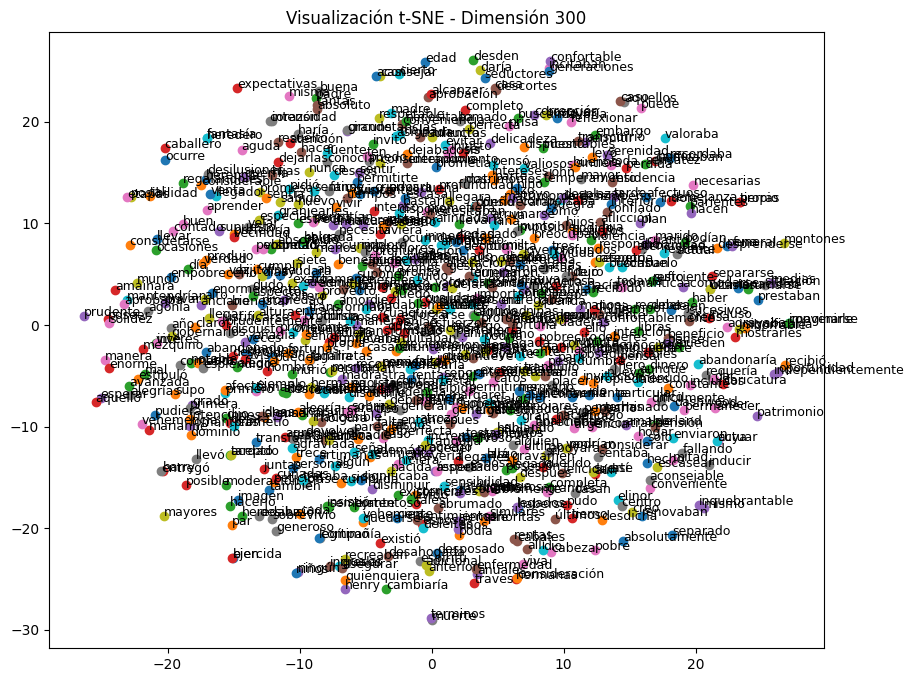

In [ ]:
# Visualizar para el modelo de dimensión 30 con perplexity ajustada
modelo_dim_30 = entrenar_modelo(50)
visualizar_tsne(modelo_dim_30, 300, perplexity=30)